# Clusterização com K-means: engajamento de posts de vendedores no Facebook Live

**Trabalho prático: Clusterização com K-means**
**Grupo:** _(nomes dos integrantes)_

**Dataset:** [Facebook Live Sellers in Thailand](https://archive.ics.uci.edu/dataset/488/facebook+live+sellers+in+thailand), UCI Machine Learning Repository (id 488, tarefa: *Clustering*).

**Pergunta:** que tipos de post existem quando olhamos só para o engajamento que cada um recebe (comentários, compartilhamentos e reações)?

O notebook segue as seis etapas pedidas:

1. Conhecer os dados
2. Preparar a matriz **X**
3. Rodar o K-means
4. Escolher *k*
5. Interpretar os grupos
6. Avaliar criticamente

In [1]:
import warnings
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42                      # semente fixa: resultados reproduzíveis
PASTA_DADOS = Path("data")
PASTA_FIG = Path("figuras")
PASTA_RES = Path("resultados")
for p in (PASTA_DADOS, PASTA_FIG, PASTA_RES):
    p.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")

# Paleta categórica (os 3 primeiros tons são distinguíveis também por daltônicos)
AZUL, LARANJA, VERDE_AGUA, AMARELO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
CORES = [AZUL, LARANJA, VERDE_AGUA, AMARELO]
TINTA, TINTA2, CINZA, GRADE, FUNDO = "#0b0b0b", "#52514e", "#9a9893", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": GRADE, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlecolor": TINTA, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10.5, "legend.frameon": False, "figure.dpi": 110,
    "savefig.dpi": 160, "savefig.bbox": "tight", "lines.linewidth": 2,
})

def salvar(fig, nome):
    fig.savefig(PASTA_FIG / nome)

from matplotlib.lines import Line2D
def alca(cor, rotulo, marker="o", ms=8):
    # marcador da legenda com tamanho e opacidade fixos (independente do gráfico)
    return Line2D([], [], color=cor, marker=marker, ls="", ms=ms, label=rotulo)

virgula = FuncFormatter(lambda v, _: f"{v:.2f}".replace(".", ","))
milhar = FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))

## 1. Conhecer os dados

**Origem.** Os dados foram coletados por N. Dehouche (*Data in Brief*, 2020, doi:10.1016/j.dib.2020.105661) das páginas de Facebook de **10 vendedores tailandeses de moda e cosméticos** que usam o Facebook Live para vender. O período vai de julho de 2012 a junho de 2018.

**O que é cada linha:** um **post** publicado em uma dessas páginas, com o tipo do post, a data e quanto engajamento ele recebeu.

| Atributo | Tipo | Unidade | Descrição | Uso no trabalho |
|---|---|---|---|---|
| `status_id` | identificador (inteiro) | — | número sequencial do post | **removido** (identificador) |
| `status_type` | categórico, 4 níveis | — | tipo do post: `video`, `photo`, `status` (só texto) ou `link` | fora de **X**; usado só na verificação (seção 6) |
| `status_published` | data e hora | mm/dd/aaaa hh:mm | momento da publicação | usado só para filtrar o período (seção 2.1) |
| `num_reactions` | numérico discreto | nº de reações | total de reações = curtir + amei + uau + haha + triste + grr | **removido** (redundante, seção 2.3) |
| `num_comments` | numérico discreto | nº de comentários | comentários recebidos | **em X** |
| `num_shares` | numérico discreto | nº de compartilhamentos | compartilhamentos recebidos | **em X** |
| `num_likes` | numérico discreto | nº de reações "Curtir" | curtidas | **em X** |
| `num_loves` | numérico discreto | nº de reações "Amei" | reação "Amei" | **em X** |
| `num_wows` | numérico discreto | nº de reações "Uau" | reação "Uau" | somado em `num_outras` |
| `num_hahas` | numérico discreto | nº de reações "Haha" | reação "Haha" | somado em `num_outras` |
| `num_sads` | numérico discreto | nº de reações "Triste" | reação "Triste" | somado em `num_outras` |
| `num_angrys` | numérico discreto | nº de reações "Grr" | reação "Grr" | somado em `num_outras` |

O dataset **não tem rótulo de grupo**. O `status_type` não é a resposta que procuramos, mas serve para conferir os grupos **depois** do agrupamento.

In [2]:
ARQ = PASTA_DADOS / "facebook_live_sellers_thailand.csv"
if ARQ.exists():
    bruto = pd.read_csv(ARQ)
else:                                   # primeira execução: baixa direto da UCI
    from ucimlrepo import fetch_ucirepo
    bruto = fetch_ucirepo(id=488).data.original
    bruto.to_csv(ARQ, index=False)

bruto["data_publicacao"] = pd.to_datetime(bruto["status_published"], format="%m/%d/%Y %H:%M")
print(f"{bruto.shape[0]} linhas x {bruto.shape[1] - 1} colunas originais")
print("Período:", bruto["data_publicacao"].min().date(), "a", bruto["data_publicacao"].max().date())
bruto.head()

7050 linhas x 12 colunas originais
Período: 2012-07-15 a 2018-06-13


,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,data_publicacao
0,1,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,2018-04-22 06:00:00
1,2,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,2018-04-21 22:45:00
2,3,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,2018-04-21 06:17:00
3,4,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,2018-04-21 02:29:00
4,5,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,2018-04-18 03:22:00


In [3]:
print(bruto["status_type"].value_counts().to_string(), "\n")
bruto.drop(columns=["status_id", "data_publicacao"]).describe().T

status_type
photo     4288
video     2334
status     365
link        63 



,count,mean,std,min,25%,50%,75%,max
num_reactions,7050.000,230.117,462.625,0.000,17.000,59.500,219.000,4710.000
num_comments,7050.000,224.356,889.637,0.000,0.000,4.000,23.000,20990.000
num_shares,7050.000,40.023,131.600,0.000,0.000,0.000,4.000,3424.000
num_likes,7050.000,215.043,449.472,0.000,17.000,58.000,184.750,4710.000
num_loves,7050.000,12.729,39.973,0.000,0.000,0.000,3.000,657.000
num_wows,7050.000,1.289,8.720,0.000,0.000,0.000,0.000,278.000
num_hahas,7050.000,0.696,3.957,0.000,0.000,0.000,0.000,157.000
num_sads,7050.000,0.244,1.597,0.000,0.000,0.000,0.000,51.000
num_angrys,7050.000,0.113,0.727,0.000,0.000,0.000,0.000,31.000


Duas coisas chamam a atenção já na descrição:

* **Escalas muito diferentes:** há posts com 20.990 comentários, enquanto a mediana é 4. `num_sads` e `num_angrys` quase sempre valem 0.
* **Assimetria forte:** em todas as colunas a média fica bem acima da mediana. Poucos posts "virais" puxam a média para cima.

## 2. Preparar a matriz X

### 2.1 Valores ausentes

Não há nenhum `NaN` no arquivo. Mesmo assim existe um **ausente disfarçado de zero**: as reações "Amei", "Uau", "Haha", "Triste" e "Grr" só foram lançadas pelo Facebook em **24/02/2016**. Nos posts anteriores, `num_loves = 0` não quer dizer que ninguém amou o post, quer dizer que o botão não existia. A tabela abaixo confirma isso nos dados.

In [4]:
print("Valores NaN no arquivo inteiro:", int(bruto.isna().sum().sum()))

LANCAMENTO_REACOES = pd.Timestamp("2016-02-24")
REACOES_NOVAS = ["num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]
antes = bruto["data_publicacao"] < LANCAMENTO_REACOES
tem_reacao_nova = bruto[REACOES_NOVAS].sum(axis=1) > 0
pd.DataFrame({
    "posts": [antes.sum(), (~antes).sum()],
    "% com alguma reação além de Curtir": [100 * tem_reacao_nova[antes].mean(), 100 * tem_reacao_nova[~antes].mean()],
}, index=["antes de 24/02/2016", "a partir de 24/02/2016"])

Valores NaN no arquivo inteiro: 0


,posts,% com alguma reação além de Curtir
antes de 24/02/2016,1720,0.000
a partir de 24/02/2016,5330,58.049


**Decisão: remover os posts anteriores a 24/02/2016.** Nenhum desses posts tem qualquer reação nova, contra 58 % dos posts posteriores. Consideramos as alternativas:

* *imputar* não faz sentido: o comportamento "Amei" não existia, não há valor verdadeiro a estimar;
* *descartar as colunas* de reações jogaria fora o "Amei", um dos sinais mais informativos;
* *manter os zeros* faria o K-means separar os posts **por época** em vez de por engajamento.

A remoção mantém 5.330 posts de um período homogêneo (fev/2016 a jun/2018).

In [5]:
dados = bruto.loc[~antes].copy()
print("Posts mantidos após o filtro de período:", len(dados))

Posts mantidos após o filtro de período: 5330


### 2.2 Linhas duplicadas

Algumas linhas são idênticas em tudo (data, hora, tipo e todas as contagens) e só diferem no `status_id`. São duplicatas da coleta, não posts diferentes, então ficamos com uma cópia de cada.

In [6]:
colunas_conteudo = bruto.columns.drop("status_id")
n_dup = int(dados.duplicated(subset=colunas_conteudo).sum())
dados = dados.drop_duplicates(subset=colunas_conteudo).reset_index(drop=True)
print(f"Duplicatas removidas: {n_dup}  ->  posts restantes: {len(dados)}")

Duplicatas removidas: 54  ->  posts restantes: 5276


### 2.3 Identificadores, rótulos e colunas redundantes

* `status_id` é um **identificador**: um número sequencial não descreve o post, e o K-means não pode usá-lo.
* `status_type` funciona como **rótulo** para verificação, então fica fora de **X** (veja 2.4).
* `status_published` só serviu para o filtro de período.
* `num_reactions` é a **soma** das seis reações. Mantê-la faria as curtidas contarem duas vezes na distância.

In [7]:
REACOES = ["num_likes", "num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]
soma = dados[REACOES].sum(axis=1)
print(f"num_reactions == soma das 6 reações em {100 * (soma == dados['num_reactions']).mean():.1f}% dos posts")
print(f"correlação entre num_reactions e num_likes: {dados['num_reactions'].corr(dados['num_likes']):.3f}")

num_reactions == soma das 6 reações em 99.8% dos posts
correlação entre num_reactions e num_likes: 0.988


### 2.4 Atributo categórico (`status_type`)

A codificação **one-hot** transforma o tipo em quatro colunas 0/1:

In [8]:
onehot = pd.get_dummies(dados["status_type"], prefix="tipo", dtype=int)
pd.concat([dados["status_type"], onehot], axis=1).head()

,status_type,tipo_link,tipo_photo,tipo_status,tipo_video
0,video,0,0,0,1
1,photo,0,1,0,0
2,video,0,0,0,1
3,photo,0,1,0,0
4,photo,0,1,0,0


**Decisão: deixar o `status_type` fora de X.** O objetivo é agrupar os posts **pelo engajamento**. Se o tipo entrar como colunas 0/1 padronizadas, a distância entre um vídeo e uma foto passa a ser enorme em qualquer caso, e os grupos simplesmente reproduzem o tipo do post. A seção 6.2 testa isso e confirma. Assim, o tipo vira uma **verificação independente**: se os grupos de engajamento tiverem relação com o tipo, isso é um achado, não algo que forçamos.

### 2.5 Reações raras

"Uau", "Haha", "Triste" e "Grr" são zero na maior parte dos posts. Cada uma sozinha é quase constante e, depois de padronizada, os poucos valores diferentes de zero ganham um peso exagerado. Por isso elas foram **somadas em uma coluna só, `num_outras`** ("outras reações").

In [9]:
RARAS = ["num_wows", "num_hahas", "num_sads", "num_angrys"]
print((dados[["num_comments", "num_shares", "num_likes", "num_loves"] + RARAS] == 0)
      .mean().mul(100).round(1).rename("% de posts com valor 0").to_string())
dados["num_outras"] = dados[RARAS].sum(axis=1)

ATRIBUTOS = ["num_comments", "num_shares", "num_likes", "num_loves", "num_outras"]
NOMES = {"num_comments": "Comentários", "num_shares": "Compartilhamentos", "num_likes": "Curtidas",
         "num_loves": "Amei", "num_outras": "Outras reações"}

num_comments   35.800
num_shares     51.300
num_likes       2.300
num_loves      47.500
num_wows       67.700
num_hahas      78.800
num_sads       88.700
num_angrys     92.000


### 2.6 Transformação logarítmica

As contagens são muito assimétricas. O K-means usa distância euclidiana ao quadrado, então os poucos posts com milhares de comentários dominariam o resultado: viraria um grupo "viral" pequeno e outro com todo o resto (a seção 6.1 mostra isso). Por isso aplicamos **log(1 + x)** antes de padronizar. O "+1" mantém o zero em zero. Na prática, o log mede **ordem de grandeza**: 10 → 100 comentários pesa o mesmo que 100 → 1.000.

In [10]:
L = np.log1p(dados[ATRIBUTOS].astype(float))
pd.DataFrame({"assimetria (original)": dados[ATRIBUTOS].skew(), "assimetria (log1p)": L.skew()}).rename(index=NOMES)

,assimetria (original),assimetria (log1p)
Comentários,7.836,0.905
Compartilhamentos,6.175,1.224
Curtidas,5.550,-0.301
Amei,5.198,1.109
Outras reações,12.238,1.559


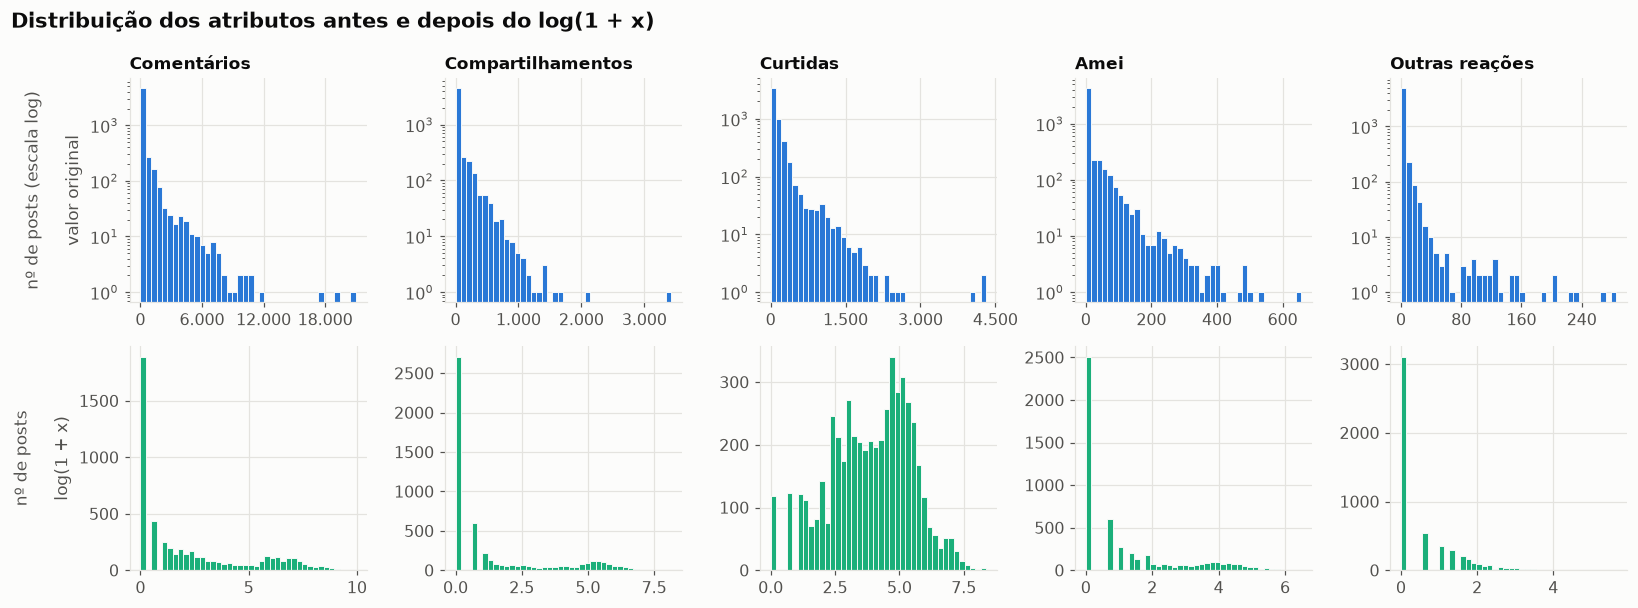

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(15, 5.6))
for j, c in enumerate(ATRIBUTOS):
    axes[0, j].hist(dados[c], bins=40, color=AZUL, edgecolor=FUNDO, linewidth=0.6)
    axes[0, j].set_title(NOMES[c], fontsize=11)
    axes[1, j].hist(L[c], bins=40, color=VERDE_AGUA, edgecolor=FUNDO, linewidth=0.6)
    axes[0, j].set_yscale("log")
    axes[0, j].xaxis.set_major_locator(plt.MaxNLocator(4))
    axes[0, j].xaxis.set_major_formatter(milhar)
axes[0, 0].set_ylabel("nº de posts (escala log)\n\nvalor original")
axes[1, 0].set_ylabel("nº de posts\n\nlog(1 + x)")
fig.suptitle("Distribuição dos atributos antes e depois do log(1 + x)", x=0.01, ha="left", fontsize=14, fontweight="bold", color=TINTA)
fig.tight_layout()
salvar(fig, "01_distribuicoes_log.png")
plt.show()

### 2.7 Padronização z = (x − μ) / σ

Cada coluna (já em log) é padronizada com a sua média μ e o seu desvio padrão σ. Depois disso, todas têm média 0 e desvio 1 e **contribuem com o mesmo peso** para a distância. Calculamos à mão e conferimos com o `StandardScaler` do scikit-learn.

In [12]:
mu = L.mean()
sigma = L.std(ddof=0)                     # desvio populacional, igual ao StandardScaler
Z = (L - mu) / sigma
X = Z.to_numpy()

scaler = StandardScaler().fit(L)
assert np.allclose(X, scaler.transform(L)), "padronização manual difere do StandardScaler"

pd.DataFrame({"μ (em log1p)": mu, "σ (em log1p)": sigma}).rename(index=NOMES)

,μ (em log1p),σ (em log1p)
Comentários,2.317,2.605
Compartilhamentos,1.455,2.058
Curtidas,3.883,1.610
Amei,1.254,1.609
Outras reações,0.648,0.944


**Exemplo de antes e depois** para dois posts (um vídeo e uma foto):

In [13]:
linhas = []
for i in [0, 1]:
    rotulo = f"post {i} ({dados.loc[i, 'status_type']})"
    linhas.append(pd.Series(dados.loc[i, ATRIBUTOS].astype(float).to_numpy(), index=ATRIBUTOS, name=(rotulo, "1. original")))
    linhas.append(pd.Series(L.loc[i].to_numpy(), index=ATRIBUTOS, name=(rotulo, "2. log(1 + x)")))
    linhas.append(pd.Series(Z.loc[i].to_numpy(), index=ATRIBUTOS, name=(rotulo, "3. z = (x - μ) / σ")))
exemplo = pd.DataFrame(linhas).rename(columns=NOMES)
exemplo.index = pd.MultiIndex.from_tuples(exemplo.index, names=["post", "etapa"])
exemplo

Comentários  Compartilhamentos  Curtidas   Amei  Outras reações
post           etapa                                                                              
post 0 (video) 1. original             512.000            262.000   432.000 92.000           5.000
               2. log(1 + x)             6.240              5.572     6.071  4.533           1.792
               3. z = (x - μ) / σ        1.506              2.000     1.359  2.038           1.212
post 1 (photo) 1. original               0.000              0.000   150.000  0.000           0.000
               2. log(1 + x)             0.000              0.000     5.017  0.000           0.000
               3. z = (x - μ) / σ       -0.890             -0.707     0.705 -0.780          -0.687

In [14]:
print("Média e desvio de cada coluna de X depois da padronização:")
print(Z.agg(["mean", "std"]).rename(columns=NOMES).round(3).to_string())
n, d = X.shape
print(f"\nMatriz final X: n = {n} posts  x  d = {d} atributos")

Média e desvio de cada coluna de X depois da padronização:
      Comentários  Compartilhamentos  Curtidas  Amei  Outras reações
mean        0.000              0.000     0.000 0.000           0.000
std         1.000              1.000     1.000 1.000           1.000

Matriz final X: n = 5276 posts  x  d = 5 atributos


**Matriz final:** **X** tem **n = 5.276** linhas (posts) e **d = 5** colunas: comentários, compartilhamentos, curtidas, "Amei" e outras reações, todas em log(1 + x) e padronizadas.

Resumo do que saiu e por quê: 1.720 posts anteriores às reações (ausente estrutural), 54 duplicatas, `status_id` (identificador), `num_reactions` (redundante), `status_type` (fica para a verificação) e `status_published` (usada só no filtro).

## 3. Rodar o K-means

### 3.1 Os passos do algoritmo

Dado *k*, o K-means procura *k* centroides μ₁, …, μₖ que minimizem a **soma dos quadrados dentro dos grupos**:

$$J = \sum_{j=1}^{k} \sum_{x_i \in C_j} \lVert x_i - \mu_j \rVert^2$$

1. **Inicialização (k-means++).** O primeiro centroide é um ponto sorteado. Cada centroide seguinte é sorteado com probabilidade proporcional a D(x)², a distância ao quadrado até o centroide mais próximo já escolhido. Assim os centroides iniciais ficam espalhados.
2. **Atribuição.** Cada ponto vai para o grupo do centroide mais próximo (distância euclidiana).
3. **Atualização.** Cada centroide passa a ser a média dos pontos do seu grupo.
4. **Repetição.** Os passos 2 e 3 se repetem até nenhum ponto trocar de grupo. Nenhum dos dois passos aumenta J, então o algoritmo sempre converge, mas pode parar em um **mínimo local**.
5. **Várias inicializações.** Por causa do mínimo local, rodamos o algoritmo **10 vezes** com sorteios diferentes e ficamos com o resultado de menor J.

### 3.2 Implementação passo a passo

Para mostrar cada passo, escrevemos o algoritmo do zero em NumPy e depois conferimos com o scikit-learn.

In [15]:
def inicializa_kmeanspp(X, k, rng):
    # Passo 1: k-means++
    centros = [X[rng.integers(len(X))]]
    for _ in range(1, k):
        d2 = np.min(((X[:, None, :] - np.array(centros)[None, :, :]) ** 2).sum(axis=2), axis=1)
        centros.append(X[rng.choice(len(X), p=d2 / d2.sum())])
    return np.array(centros)


def kmeans_do_zero(X, k, n_init=10, max_iter=300, seed=SEED):
    rng = np.random.default_rng(seed)
    melhor, historicos = None, []
    for _ in range(n_init):                                     # Passo 5: várias inicializações
        C = inicializa_kmeanspp(X, k, rng)
        historico, rot_anterior = [], None
        for _ in range(max_iter):
            D = ((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)   # distâncias ao quadrado (n x k)
            rot = D.argmin(axis=1)                                   # Passo 2: atribuição
            historico.append(D[np.arange(len(X)), rot].sum())        # J nesta iteração
            if rot_anterior is not None and np.array_equal(rot, rot_anterior):
                break                                                # Passo 4: convergiu
            rot_anterior = rot
            C = np.array([X[rot == j].mean(axis=0) if np.any(rot == j) else C[j]
                          for j in range(k)])                        # Passo 3: atualização
        historicos.append(historico)
        if melhor is None or historico[-1] < melhor["J"]:
            melhor = {"J": historico[-1], "rotulos": rot, "centroides": C, "historico": historico}
    return melhor, historicos


melhor, historicos = kmeans_do_zero(X, k=3)
print(f"Implementação própria, k = 3: J final = {melhor['J']:.1f}  (convergiu em {len(melhor['historico'])} iterações)")

Implementação própria, k = 3: J final = 6903.9  (convergiu em 15 iterações)


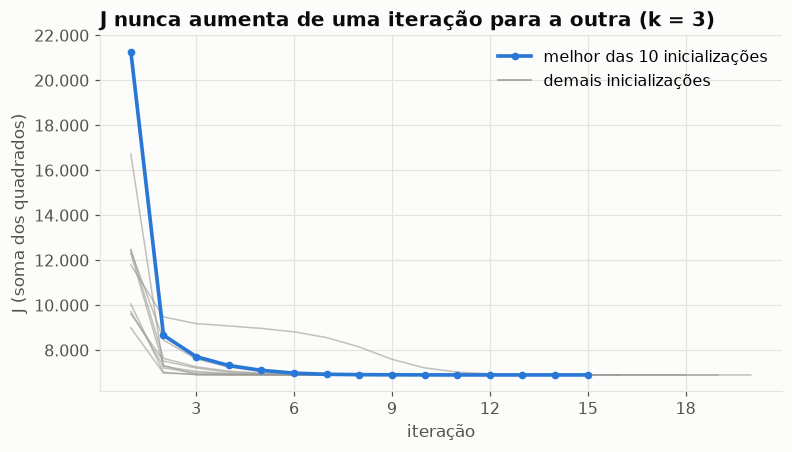

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for h in historicos:
    ax.plot(range(1, len(h) + 1), h, color=CINZA, lw=1, alpha=0.6)
h = melhor["historico"]
ax.plot(range(1, len(h) + 1), h, color=AZUL, lw=2.4, marker="o", ms=4, label="melhor das 10 inicializações")
ax.plot([], [], color=CINZA, lw=1, label="demais inicializações")
ax.set_xlabel("iteração")
ax.set_ylabel("J (soma dos quadrados)")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.yaxis.set_major_formatter(milhar)
ax.set_title("J nunca aumenta de uma iteração para a outra (k = 3)")
ax.legend()
salvar(fig, "02_convergencia_J.png")
plt.show()

### 3.3 K-means do scikit-learn (k-means++, 10 inicializações)

A partir daqui usamos `KMeans(init="k-means++", n_init=10)`. Abaixo comparamos o J final com a nossa implementação e mostramos o J de cada inicialização isolada, para ver que sorteios diferentes podem parar em mínimos diferentes.

In [17]:
km3 = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=SEED).fit(X)
print(f"scikit-learn, k = 3: J final = {km3.inertia_:.1f}  ({km3.n_iter_} iterações na melhor inicialização)")
print(f"implementação própria: J final = {melhor['J']:.1f}")
print(f"concordância entre as duas partições (ARI): {adjusted_rand_score(km3.labels_, melhor['rotulos']):.3f}")

J_por_init = [KMeans(n_clusters=3, init="k-means++", n_init=1, random_state=s).fit(X).inertia_ for s in range(10)]
pd.DataFrame({"J final": J_por_init}, index=pd.Index(range(1, 11), name="inicialização")).T

scikit-learn, k = 3: J final = 6903.9  (12 iterações na melhor inicialização)
implementação própria: J final = 6903.9
concordância entre as duas partições (ARI): 1.000


inicialização,1,2,3,4,5,6,7,8,9,10
J final,6904.126,6903.905,6903.921,6903.943,6903.905,6903.943,6904.126,6903.905,6903.905,6904.126


## 4. Escolher k

Rodamos o K-means (k-means++, 10 inicializações) para k = 1, …, 10 e guardamos J(k) e a silhueta média s̄(k).

Para cada ponto *i*, a **silhueta** é s(i) = (b − a) / max(a, b), em que *a* é a distância média de *i* aos pontos do próprio grupo e *b* é a distância média aos pontos do grupo vizinho mais próximo. s(i) perto de 1 indica ponto bem atribuído, perto de 0 indica ponto na fronteira e **negativo** indica que o ponto estaria melhor no grupo vizinho.

In [18]:
modelos, linhas = {}, []
for k in range(1, 11):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(X)
    modelos[k] = km
    linhas.append({"k": k, "J(k)": km.inertia_,
                   "s̄(k)": silhouette_score(X, km.labels_) if k > 1 else np.nan})
res_k = pd.DataFrame(linhas).set_index("k")
res_k["queda de J em relação a k-1 (%)"] = -100 * res_k["J(k)"].pct_change()

# Cotovelo objetivo: ponto da curva normalizada mais distante da reta entre k=1 e k=10
kk = res_k.index.to_numpy(dtype=float)
JJ = res_k["J(k)"].to_numpy()
xn, yn = (kk - kk.min()) / (kk.max() - kk.min()), (JJ - JJ.min()) / (JJ.max() - JJ.min())
res_k["distância à reta (cotovelo)"] = np.abs(xn + yn - 1) / np.sqrt(2)
k_cotovelo = int(res_k["distância à reta (cotovelo)"].idxmax())
k_silhueta = int(res_k["s̄(k)"].idxmax())
print(f"cotovelo (máxima distância à reta): k = {k_cotovelo}   |   maior silhueta média: k = {k_silhueta}")
res_k

cotovelo (máxima distância à reta): k = 3   |   maior silhueta média: k = 2


,J(k),s̄(k),queda de J em relação a k-1 (%),distância à reta (cotovelo)
k,,,,
1,26380.000,NaN,NaN,0.000
2,10371.007,0.570,60.686,0.407
3,6903.905,0.452,33.431,0.434
4,5765.861,0.384,16.484,0.390
5,4824.270,0.369,16.330,0.340
6,4178.537,0.334,13.385,0.281
7,3823.489,0.319,8.497,0.213
8,3505.519,0.319,8.316,0.144
9,3262.857,0.300,6.922,0.073


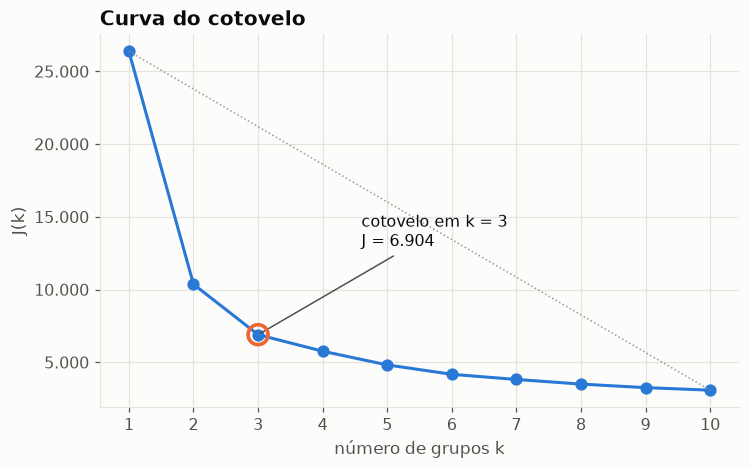

In [19]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.plot(res_k.index, res_k["J(k)"], color=AZUL, marker="o", ms=7)
ax.plot([1, 10], [JJ[0], JJ[-1]], color=CINZA, lw=1, ls=":")
ax.scatter([k_cotovelo], [res_k.loc[k_cotovelo, "J(k)"]], s=170, facecolor="none", edgecolor=LARANJA, lw=2.4, zorder=5)
ax.annotate(f"cotovelo em k = {k_cotovelo}\nJ = {res_k.loc[k_cotovelo, 'J(k)']:,.0f}".replace(",", "."),
            xy=(k_cotovelo, res_k.loc[k_cotovelo, "J(k)"]), xytext=(4.6, 13000), color=TINTA,
            arrowprops=dict(arrowstyle="-", color=TINTA2, lw=1))
ax.set_xticks(range(1, 11))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
ax.set_xlabel("número de grupos k")
ax.set_ylabel("J(k)")
ax.set_title("Curva do cotovelo")
salvar(fig, "03_cotovelo.png")
plt.show()

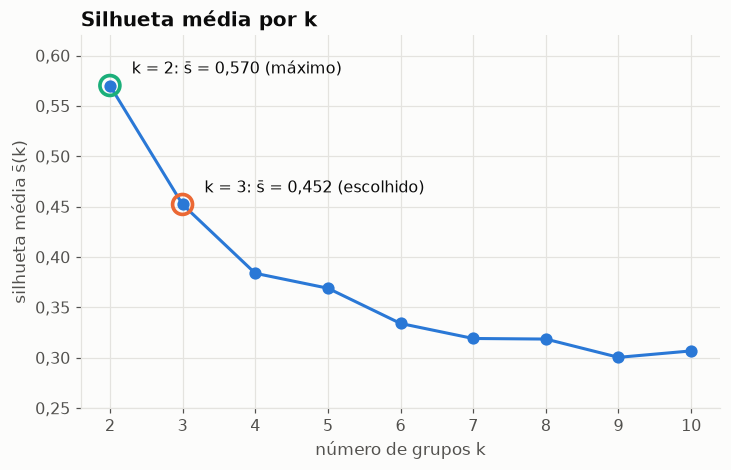

In [20]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
s_k = res_k["s̄(k)"].dropna()
ax.plot(s_k.index, s_k, color=AZUL, marker="o", ms=7)
for k, cor, txt in [(k_silhueta, VERDE_AGUA, "máximo"), (3, LARANJA, "escolhido")]:
    ax.scatter([k], [s_k[k]], s=170, facecolor="none", edgecolor=cor, lw=2.4, zorder=5)
    ax.annotate(f"k = {k}: s̄ = {s_k[k]:.3f} ({txt})".replace(".", ","), xy=(k, s_k[k]),
                xytext=(k + 0.3, s_k[k] + 0.012), color=TINTA)
ax.set_xticks(range(2, 11))
ax.set_ylim(0.25, 0.62)
ax.yaxis.set_major_formatter(virgula)
ax.set_xlabel("número de grupos k")
ax.set_ylabel("silhueta média s̄(k)")
ax.set_title("Silhueta média por k")
salvar(fig, "04_silhueta_media.png")
plt.show()

### Gráficos da silhueta para o k escolhido e os vizinhos

Para os grupos terem a mesma ordem em todos os gráficos, eles são numerados do **menor para o maior engajamento** (média do centroide em z).

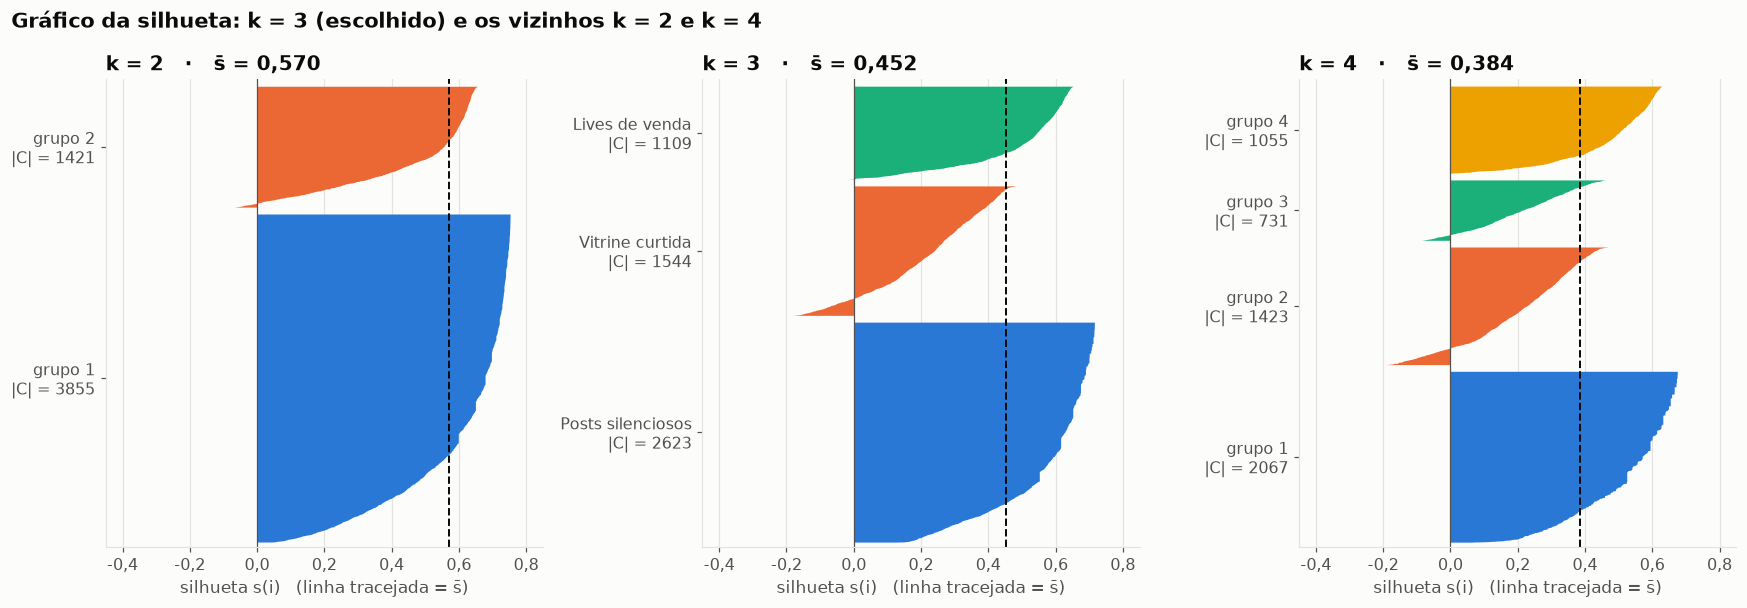

|C|  s̄ do grupo  pontos com s < 0
k grupo                                     
2 1      3855        0.610                 0
  2      1421        0.462                47
3 1      2623        0.577                 0
  2      1544        0.214               205
  3      1109        0.488                 6
4 1      2067        0.527                 0
  2      1423        0.201               203
  3       731        0.208                70
  4      1055        0.472                 1

In [21]:
def ordenar(km):
    # renumera os grupos do menor para o maior engajamento médio
    ordem = np.argsort(km.cluster_centers_.mean(axis=1))
    novo = np.empty_like(ordem)
    novo[ordem] = np.arange(len(ordem))
    return novo[km.labels_], km.cluster_centers_[ordem]


NOMES_GRUPOS = {3: ["Posts silenciosos", "Vitrine curtida", "Lives de venda"]}

def grafico_silhueta(ax, X, rot, k, nomes=None):
    s = silhouette_samples(X, rot)
    y0, centros_y = 0, []
    for j in range(k):
        sj = np.sort(s[rot == j])
        ax.fill_betweenx(np.arange(y0, y0 + len(sj)), 0, sj, color=CORES[j], linewidth=0)
        centros_y.append(y0 + len(sj) / 2)
        y0 += len(sj) + 80
    ax.axvline(s.mean(), color=TINTA, ls="--", lw=1.3)
    ax.axvline(0, color=TINTA2, lw=0.8)
    rotulos = nomes if nomes else [f"grupo {j + 1}" for j in range(k)]
    ax.set_yticks(centros_y)
    ax.set_yticklabels([f"{r}\n|C| = {np.sum(rot == j)}" for j, r in enumerate(rotulos)])
    ax.set_xlim(-0.45, 0.85)
    ax.set_ylim(-60, y0)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("silhueta s(i)   (linha tracejada = s̄)")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
    ax.set_title(f"k = {k}   ·   s̄ = {s.mean():.3f}".replace(".", ","))
    return s


fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
silhuetas = {}
for ax, k in zip(axes, [2, 3, 4]):
    rot_k, _ = ordenar(modelos[k])
    silhuetas[k] = (rot_k, grafico_silhueta(ax, X, rot_k, k, NOMES_GRUPOS.get(k)))
fig.suptitle("Gráfico da silhueta: k = 3 (escolhido) e os vizinhos k = 2 e k = 4",
             x=0.01, ha="left", fontsize=14, fontweight="bold", color=TINTA)
fig.tight_layout()
salvar(fig, "05_silhueta_k2_k3_k4.png")
plt.show()

resumo_sil = []
for k, (rot_k, s) in silhuetas.items():
    for j in range(k):
        resumo_sil.append({"k": k, "grupo": j + 1, "|C|": int(np.sum(rot_k == j)),
                           "s̄ do grupo": s[rot_k == j].mean(), "pontos com s < 0": int(np.sum(s[rot_k == j] < 0))})
pd.DataFrame(resumo_sil).set_index(["k", "grupo"])

### Justificativa da escolha: **k = 3**

Os dois métodos não apontam para o mesmo k. O **cotovelo** fica em k = 3: J cai 61 % de k = 1 para k = 2 e mais 33 % de k = 2 para k = 3. A partir daí cada grupo extra reduz J em no máximo 16 %, e o critério da maior distância à reta também escolhe k = 3. A **silhueta média** é máxima em **k = 2** (s̄ = 0,570), mas continua razoável em k = 3 (s̄ = 0,452) e cai para 0,384 em k = 4.

Eles discordam porque medem coisas diferentes. J sempre diminui com k e só indica onde o ganho deixa de compensar. A silhueta premia grupos **bem separados**, e com k = 2 a divisão é a mais nítida possível: posts com conversa (comentários e compartilhamentos) contra posts sem conversa. Os gráficos da silhueta mostram o preço de k = 3: o grupo do meio ("Vitrine curtida") tem s̄ baixo e concentra quase todos os pontos negativos, porque fica entre os outros dois.

Escolhemos **k = 3** porque o terceiro grupo responde à pergunta do trabalho. Com k = 2, o post típico da "Vitrine curtida" (≈ 150 curtidas e 10 comentários) fica no mesmo grupo do post típico silencioso (≈ 12 curtidas e nenhum comentário), e isso esconde a diferença entre "foto que agrada" e "post ignorado". Com k = 4 a silhueta cai mais, surge um segundo grupo fraco (s̄ ≈ 0,2) e os grupos novos só dividem o grupo do meio em "um pouco mais" e "um pouco menos" curtido.

## 5. Interpretar os grupos

### 5.1 Tamanho e centroides na unidade original

Para voltar à unidade original desfazemos as duas transformações, na ordem inversa:

1. **desfazer a padronização:** log1p(x) = z · σ + μ
2. **desfazer o log:** x = exp(log1p(x)) − 1

O centroide desfeito é uma média geométrica, ou seja, o **post típico** do grupo, e não se deixa levar pelos poucos posts virais. Mostramos também a média aritmética e a mediana de cada grupo na unidade original.

In [22]:
k_final = 3
rotulos, centros_z = ordenar(modelos[k_final])
nomes = NOMES_GRUPOS[k_final]
dados["grupo"] = rotulos
dados["nome_grupo"] = [nomes[r] for r in rotulos]

centros_log = centros_z * sigma.to_numpy() + mu.to_numpy()     # desfaz a padronização
centros_orig = np.expm1(centros_log)                           # desfaz o log(1 + x)

tab_centroides = pd.DataFrame(centros_orig, columns=[NOMES[c] for c in ATRIBUTOS], index=nomes)
tab_centroides.insert(0, "% dos posts", 100 * np.bincount(rotulos) / len(rotulos))
tab_centroides.insert(0, "|C_k|", np.bincount(rotulos))
tab_centroides.index.name = "grupo"
print(f"J final (k = {k_final}): {modelos[k_final].inertia_:.1f}")
print("\nCentroides na unidade original (contagem por post):")
tab_centroides.round(1)

J final (k = 3): 6903.9

Centroides na unidade original (contagem por post):


,|C_k|,% dos posts,Comentários,Compartilhamentos,Curtidas,Amei,Outras reações
grupo,,,,,,,
Posts silenciosos,2623,49.700,0.500,0.300,12.200,0.100,0.000
Vitrine curtida,1544,29.300,11.000,1.600,155.800,2.500,1.300
Lives de venda,1109,21.000,749.700,151.600,208.000,50.900,5.100


In [23]:
media = dados.groupby("nome_grupo")[ATRIBUTOS].mean().loc[nomes].rename(columns=NOMES)
mediana = dados.groupby("nome_grupo")[ATRIBUTOS].median().loc[nomes].rename(columns=NOMES)
print("Média aritmética por grupo (puxada por posts virais):")
print(media.round(1).to_string())
print("\nMediana por grupo:")
print(mediana.round(1).to_string())
print("\nCentroides em z (desvios padrão em relação à média):")
pd.DataFrame(centros_z, columns=[NOMES[c] for c in ATRIBUTOS], index=nomes).round(2)

Média aritmética por grupo (puxada por posts virais):
                   Comentários  Compartilhamentos  Curtidas   Amei  Outras reações
nome_grupo                                                                        
Posts silenciosos        1.100              0.600    19.900  0.200           0.100
Vitrine curtida         31.700              4.700   209.900  4.100           2.500
Lives de venda        1355.500            241.800   325.800 74.300          10.800

Mediana por grupo:
                   Comentários  Compartilhamentos  Curtidas   Amei  Outras reações
nome_grupo                                                                        
Posts silenciosos        0.000              0.000    15.000  0.000           0.000
Vitrine curtida         10.000              1.000   149.500  2.000           1.000
Lives de venda         755.000            182.000   174.000 52.000           4.000

Centroides em z (desvios padrão em relação à média):


,Comentários,Compartilhamentos,Curtidas,Amei,Outras reações
Posts silenciosos,-0.740,-0.590,-0.810,-0.700,-0.640
Vitrine curtida,0.060,-0.240,0.730,-0.000,0.210
Lives de venda,1.650,1.740,0.910,1.670,1.220


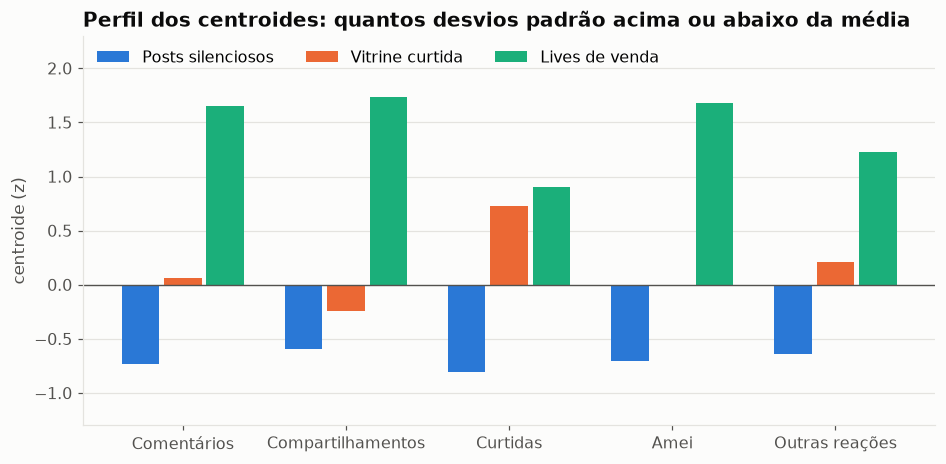

In [24]:
fig, ax = plt.subplots(figsize=(10, 4.6))
largura = 0.26
xs = np.arange(len(ATRIBUTOS))
for j, nome in enumerate(nomes):
    ax.bar(xs + (j - 1) * largura, centros_z[j], width=largura - 0.03, color=CORES[j], label=nome)
ax.axhline(0, color=TINTA2, lw=0.9)
ax.set_xticks(xs)
ax.set_xticklabels([NOMES[c] for c in ATRIBUTOS])
ax.set_ylabel("centroide (z)")
ax.grid(axis="x", visible=False)
ax.legend(ncol=3, loc="upper left")
ax.set_ylim(-1.3, 2.3)
ax.set_title("Perfil dos centroides: quantos desvios padrão acima ou abaixo da média")
salvar(fig, "08_perfil_centroides.png")
plt.show()

### 5.2 Nome e descrição de cada grupo

| Grupo | Nome | Descrição |
|---|---|---|
| 1 | **Posts silenciosos** | Quase metade dos posts (≈ 50 %). O post típico recebe cerca de **12 curtidas** e praticamente nenhum comentário, compartilhamento ou "Amei". Ninguém conversa com esses posts. |
| 2 | **Vitrine curtida** | Cerca de 29 % dos posts, na maioria **fotos**. Recebem bastante curtida (≈ **156** por post típico), mas pouca conversa (≈ 11 comentários e 2 compartilhamentos). São posts de vitrine: o produto agrada, mas não gera interação. |
| 3 | **Lives de venda** | Cerca de 21 % dos posts, quase todos **vídeos**. Recebem **≈ 750 comentários** e **≈ 150 compartilhamentos** por post típico, além do maior número de curtidas e de "Amei". É o engajamento das transmissões ao vivo, em que o público comenta e compartilha. Uma explicação plausível é que, nas vendas por live, o pedido costuma ser feito nos comentários. |

### 5.3 Visualização em 2D

variância explicada: CP1 = 78.1%, CP2 = 10.4%, total = 88.5%
                    CP1    CP2
Comentários       0.476 -0.220
Compartilhamentos 0.453 -0.503
Curtidas          0.401  0.732
Amei              0.477 -0.220
Outras reações    0.424  0.339


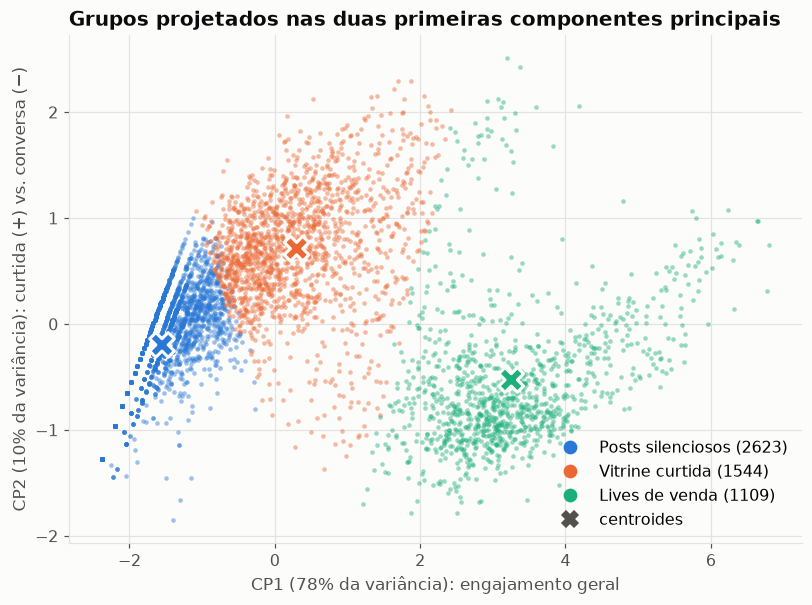

In [25]:
pca = PCA(n_components=2, random_state=SEED).fit(X)
P = pca.transform(X)
Pc = pca.transform(centros_z)
var = pca.explained_variance_ratio_
print(f"variância explicada: CP1 = {100 * var[0]:.1f}%, CP2 = {100 * var[1]:.1f}%, total = {100 * var.sum():.1f}%")
print(pd.DataFrame(pca.components_.T, index=[NOMES[c] for c in ATRIBUTOS], columns=["CP1", "CP2"]).round(3).to_string())

fig, ax = plt.subplots(figsize=(8.6, 6))
for j, nome in enumerate(nomes):
    m = rotulos == j
    ax.scatter(P[m, 0], P[m, 1], s=9, color=CORES[j], alpha=0.45, linewidths=0)
ax.scatter(Pc[:, 0], Pc[:, 1], s=260, c=CORES[:3], marker="X", edgecolor=FUNDO, linewidths=2, zorder=5)
ax.set_xlabel(f"CP1 ({100 * var[0]:.0f}% da variância): engajamento geral")
ax.set_ylabel(f"CP2 ({100 * var[1]:.0f}% da variância): curtida (+) vs. conversa (−)")
ax.set_title("Grupos projetados nas duas primeiras componentes principais")
ax.legend(handles=[alca(CORES[j], f"{nome} ({np.sum(rotulos == j)})") for j, nome in enumerate(nomes)]
          + [alca(TINTA2, "centroides", marker="X", ms=11)], loc="lower right")
salvar(fig, "06_pca_grupos.png")
plt.show()

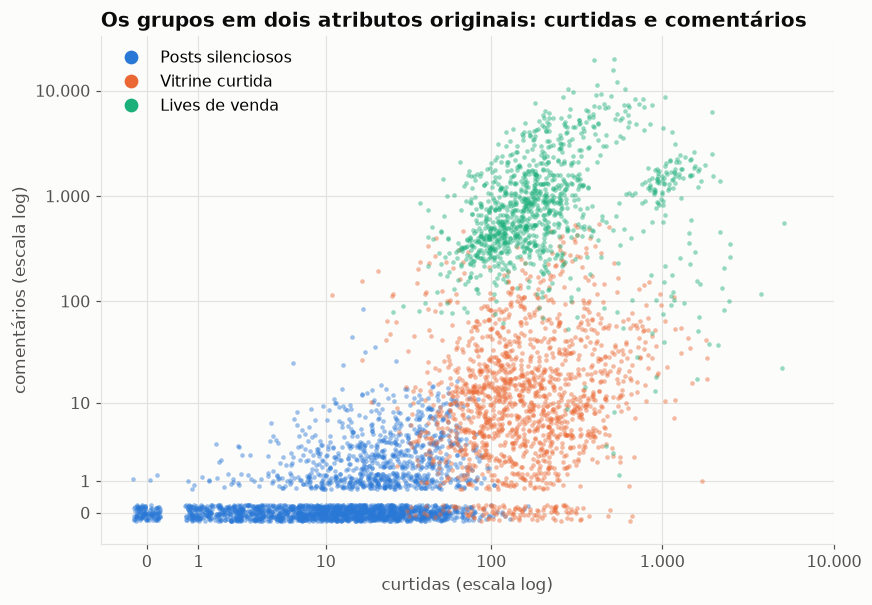

In [26]:
# Dois atributos originais. Os valores são inteiros, então somamos um "jitter" pequeno
# só no gráfico, para os pontos empilhados ficarem visíveis.
rng = np.random.default_rng(SEED)
jit = lambda v: np.log1p(v) + rng.uniform(-0.18, 0.18, len(v))
fig, ax = plt.subplots(figsize=(8.6, 6))
for j, nome in enumerate(nomes):
    m = rotulos == j
    ax.scatter(jit(dados.loc[m, "num_likes"]), jit(dados.loc[m, "num_comments"]),
               s=9, color=CORES[j], alpha=0.45, linewidths=0)
ticks = [0, 1, 10, 100, 1000, 10000]
ax.set_xticks(np.log1p(ticks)); ax.set_xticklabels([f"{t:,}".replace(",", ".") for t in ticks])
ax.set_yticks(np.log1p(ticks)); ax.set_yticklabels([f"{t:,}".replace(",", ".") for t in ticks])
ax.set_xlabel("curtidas (escala log)")
ax.set_ylabel("comentários (escala log)")
ax.set_title("Os grupos em dois atributos originais: curtidas e comentários")
ax.legend(handles=[alca(CORES[j], nome) for j, nome in enumerate(nomes)], loc="upper left")
salvar(fig, "07_curtidas_vs_comentarios.png")
plt.show()

A **CP1** tem peso positivo em todos os atributos e funciona como um eixo de "engajamento geral": os três grupos se ordenam da esquerda para a direita. A **CP2** contrapõe curtidas (peso +0,73) a compartilhamentos e comentários (pesos negativos) e separa a "Vitrine curtida" (no alto) das "Lives de venda" (embaixo). As "listras" à esquerda são posts empilhados em zero em várias colunas ao mesmo tempo. No gráfico de curtidas × comentários, os posts silenciosos se acumulam perto da origem, a vitrine se estende para a direita (muita curtida, pouco comentário) e as lives ficam no alto (muito comentário). A fronteira entre silenciosos e vitrine é contínua, sem um vazio separando os dois, e é exatamente aí que aparecem as silhuetas negativas.

## 6. Avaliar criticamente

### 6.1 Limitação 1: sensibilidade a outliers e à escala

O K-means minimiza distâncias **ao quadrado**, então um ponto muito distante pesa muito. Para medir o efeito, repetimos tudo **sem o log(1 + x)**, padronizando direto as contagens.

In [27]:
X_sem_log = StandardScaler().fit_transform(dados[ATRIBUTOS].astype(float))
comp = []
for k in [2, 3, 4]:
    km_s = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(X_sem_log)
    comp.append({"k": k,
                 "tamanhos SEM log": sorted(np.bincount(km_s.labels_).tolist(), reverse=True),
                 "s̄ SEM log": silhouette_score(X_sem_log, km_s.labels_),
                 "tamanhos COM log": sorted(np.bincount(modelos[k].labels_).tolist(), reverse=True),
                 "s̄ COM log": res_k.loc[k, "s̄(k)"]})
    if k == 3:
        rot_sem_log, _ = ordenar(km_s)
pd.DataFrame(comp).set_index("k")

,tamanhos SEM log,s̄ SEM log,tamanhos COM log,s̄ COM log
k,,,,
2,"[5036, 240]",0.830,"[3855, 1421]",0.570
3,"[4891, 352, 33]",0.783,"[2623, 1544, 1109]",0.452
4,"[4396, 722, 127, 31]",0.687,"[2067, 1423, 1055, 731]",0.384


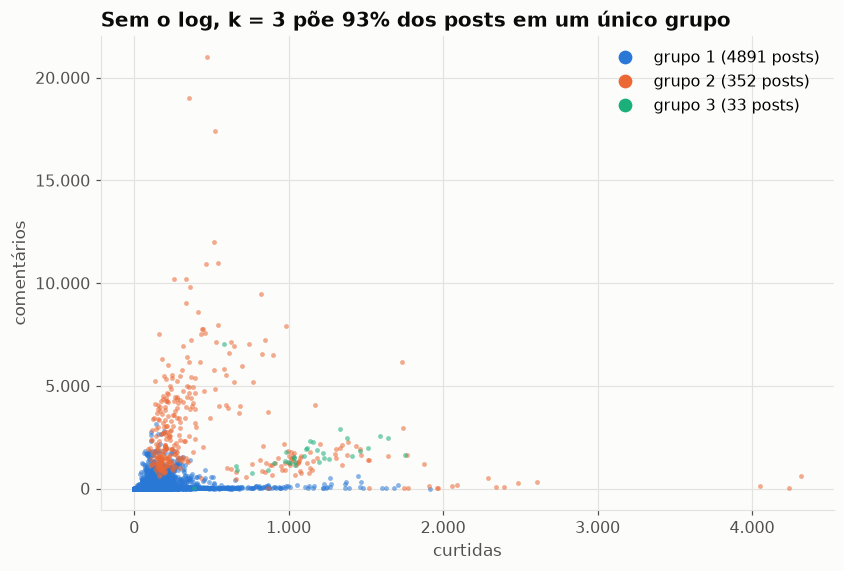

In [28]:
fig, ax = plt.subplots(figsize=(8.6, 5.6))
for j in range(3):
    m = rot_sem_log == j
    ax.scatter(dados.loc[m, "num_likes"], dados.loc[m, "num_comments"], s=10, color=CORES[j],
               alpha=0.55, linewidths=0)
ax.set_xlabel("curtidas")
ax.set_ylabel("comentários")
ax.xaxis.set_major_formatter(milhar)
ax.yaxis.set_major_formatter(milhar)
ax.set_title(f"Sem o log, k = 3 põe {100 * np.mean(rot_sem_log == 0):.0f}% dos posts em um único grupo")
ax.legend(handles=[alca(CORES[j], f"grupo {j + 1} ({np.sum(rot_sem_log == j)} posts)") for j in range(3)],
          loc="upper right")
salvar(fig, "09_sem_log_outliers.png")
plt.show()

Sem o log, a silhueta fica **mais alta** (≈ 0,8 em k = 2), mas o resultado é pior: um grupo gigante com quase todos os posts e grupos minúsculos só com os posts virais. A silhueta alta vem da distância enorme entre os virais e o resto, não de uma segmentação útil. Por isso **a silhueta sozinha não basta**, e a escolha da transformação muda completamente a resposta.

### 6.2 Limitação 2: efeito da codificação one-hot

Agora repetimos com o `status_type` em one-hot dentro de **X** (5 atributos de engajamento + 4 colunas 0/1, todos padronizados) e medimos a concordância com o tipo do post pelo **ARI** (*Adjusted Rand Index*: 0 = concordância de acaso, 1 = partições idênticas).

In [29]:
L_oh = pd.concat([L, onehot.astype(float)], axis=1)
X_oh = StandardScaler().fit_transform(L_oh)
km_oh = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=SEED).fit(X_oh)
ari_principal = adjusted_rand_score(dados["status_type"], rotulos)
ari_oh = adjusted_rand_score(dados["status_type"], km_oh.labels_)
print(f"ARI(grupos, status_type), modelo principal (sem one-hot): {ari_principal:.3f}")
print(f"ARI(grupos, status_type), com one-hot do tipo em X:       {ari_oh:.3f}\n")
print("Composição dos grupos COM one-hot (linhas = grupos, colunas = tipo do post):")
pd.crosstab(km_oh.labels_ + 1, dados["status_type"], rownames=["grupo"], colnames=["tipo"])

ARI(grupos, status_type), modelo principal (sem one-hot): 0.189
ARI(grupos, status_type), com one-hot do tipo em X:       0.798

Composição dos grupos COM one-hot (linhas = grupos, colunas = tipo do post):


tipo,link,photo,status,video
grupo,,,,
1,46,0,259,865
2,0,2944,0,0
3,0,30,11,1121


Com o one-hot, os grupos passam a **reproduzir o tipo do post** (ARI ≈ 0,8): um grupo vira exatamente o conjunto de **todas as fotos** (2.944 de 2.944), com engajamento alto ou baixo, e os outros dois dividem o resto. A diferença entre 0 e 1 em uma coluna binária padronizada é de vários desvios padrão e domina a distância. Em dados mistos, colocar ou não um atributo categórico decide o que o K-means vai encontrar. Alternativas seriam dar peso menor às colunas one-hot ou usar algoritmos próprios para dados mistos (K-prototypes, distância de Gower).

### 6.3 Limitação 3: grupos não esféricos e fronteiras contínuas

O K-means assume grupos mais ou menos **esféricos e de tamanho parecido**, porque cada ponto vai para o centroide mais próximo. Aqui o engajamento é um **contínuo**, e muitos posts estão empilhados em valores 0 (36 % não têm comentários e 51 % não têm compartilhamentos). Isso cria "pilhas" no espaço que nada têm de esféricas. A consequência aparece no grupo "Vitrine curtida":

In [30]:
s3 = silhouette_samples(X, rotulos)
D_cent = ((X[:, None, :] - centros_z[None, :, :]) ** 2).sum(axis=2)
D_cent[np.arange(len(X)), rotulos] = np.inf
vizinho = D_cent.argmin(axis=1)
mal = s3 < 0
print(f"pontos com silhueta negativa: {mal.sum()} de {len(X)} ({100 * mal.mean():.1f}%)")
pd.crosstab(pd.Series([nomes[r] for r in rotulos[mal]], name="grupo atribuído"),
            pd.Series([nomes[v] for v in vizinho[mal]], name="grupo vizinho mais próximo"))

pontos com silhueta negativa: 211 de 5276 (4.0%)


grupo vizinho mais próximo,Lives de venda,Posts silenciosos,Vitrine curtida
grupo atribuído,,,
Lives de venda,0,0,6
Vitrine curtida,3,202,0


Quase todos os pontos mal atribuídos estão na **Vitrine curtida** e têm como vizinho os **Posts silenciosos**. São posts com algumas dezenas de curtidas e um ou outro comentário, que ficam no meio do caminho entre os dois grupos. Não estão "errados": não existe uma fronteira natural ali, e o K-means precisa traçar um corte em algum lugar.

O efeito dos zeros também aparece em um caso concreto: a foto da seção 2.7 (post 1) tem **150 curtidas**, mas zero em todo o resto, e por isso cai nos **Posts silenciosos**. Os quatro zeros pesam mais na distância do que as curtidas altas.

In [31]:
print("post 1:", dados.loc[1, ATRIBUTOS].rename(NOMES).to_dict())
print(f"grupo atribuído: {dados.loc[1, 'nome_grupo']}   |   silhueta: {s3[1]:.3f}")
print("distância ao quadrado até cada centroide:",
      {nomes[j]: round(float(((X[1] - centros_z[j]) ** 2).sum()), 2) for j in range(3)})

post 1: {'Comentários': 0, 'Compartilhamentos': 0, 'Curtidas': 150, 'Amei': 0, 'Outras reações': 0}
grupo atribuído: Posts silenciosos   |   silhueta: 0.167
distância ao quadrado até cada centroide: {'Posts silenciosos': 2.34, 'Vitrine curtida': 2.53, 'Lives de venda': 22.14}


Esse é um limite do K-means com dados cheios de zeros: a distância euclidiana trata todas as colunas da mesma forma, e quatro colunas "em silêncio" superam uma coluna "falando alto".

### 6.4 Verificação com o tipo do post (feita só depois do agrupamento)

In [32]:
cruz = pd.crosstab(dados["nome_grupo"], dados["status_type"]).loc[nomes]
cruz_pct = (100 * cruz.div(cruz.sum(axis=1), axis=0)).round(1)
print("Número de posts:")
print(cruz.to_string())
print("\n% de cada tipo dentro do grupo:")
print(cruz_pct.to_string())
print(f"\nARI(grupos, status_type) = {ari_principal:.3f}")

Número de posts:
status_type        link  photo  status  video
nome_grupo                                   
Posts silenciosos    34   1760     110    719
Vitrine curtida      12   1161     148    223
Lives de venda        0     53      12   1044

% de cada tipo dentro do grupo:
status_type        link  photo  status  video
nome_grupo                                   
Posts silenciosos 1.300 67.100   4.200 27.400
Vitrine curtida   0.800 75.200   9.600 14.400
Lives de venda    0.000  4.800   1.100 94.100

ARI(grupos, status_type) = 0.189


O tipo **não** foi usado no agrupamento, e mesmo assim:

* as **Lives de venda** são cerca de **94 % vídeos**, o que confirma que o grupo de alta conversa corresponde às transmissões;
* a **Vitrine curtida** é principalmente **foto**;
* os **Posts silenciosos** misturam fotos e também muitos vídeos de baixo alcance.

O ARI baixo (≈ 0,19) é esperado e até desejável: os grupos **não** são o tipo do post. Eles juntam posts de tipos diferentes que recebem o mesmo engajamento, por exemplo um vídeo sem audiência e uma foto ignorada.

### 6.5 Outras limitações

* **Vendedor não identificado:** os dados não dizem de qual dos 10 vendedores é cada post. Uma página grande gera mais engajamento em qualquer post, então parte dos grupos pode refletir **o tamanho da página**, e não só o post.
* **Recorte temporal:** usamos só fev/2016 a jun/2018, e os grupos podem não valer para outro período ou rede social.
* **Agregação das reações raras:** somar "Uau", "Haha", "Triste" e "Grr" simplifica, mas apaga diferenças entre elas.
* **Mínimos locais:** o K-means depende da inicialização. Usamos k-means++ com 10 inicializações e semente fixa (a tabela da seção 3.3 mostra a variação de J entre inicializações).

In [33]:
resultados = {
    "n_bruto": int(len(bruto)), "n_removidos_periodo": int(antes.sum()), "n_duplicatas": n_dup,
    "n": int(n), "d": int(d), "atributos": [NOMES[c] for c in ATRIBUTOS],
    "mu_log": mu.round(4).to_dict(), "sigma_log": sigma.round(4).to_dict(),
    "J_por_k": res_k["J(k)"].round(2).to_dict(), "silhueta_por_k": res_k["s̄(k)"].round(4).dropna().to_dict(),
    "k_cotovelo": k_cotovelo, "k_silhueta": k_silhueta, "k_escolhido": k_final,
    "J_final": round(float(modelos[k_final].inertia_), 2), "J_implementacao_propria": round(float(melhor["J"]), 2),
    "J_por_inicializacao_k3": [round(float(v), 2) for v in J_por_init],
    "grupos": {nome: {"tamanho": int(np.sum(rotulos == j)),
                      "centroide_original": {NOMES[c]: round(float(centros_orig[j, i]), 2) for i, c in enumerate(ATRIBUTOS)},
                      "centroide_z": {NOMES[c]: round(float(centros_z[j, i]), 3) for i, c in enumerate(ATRIBUTOS)},
                      "silhueta": round(float(s3[rotulos == j].mean()), 4), "negativos": int(np.sum(s3[rotulos == j] < 0)),
                      "tipos_pct": cruz_pct.loc[nome].to_dict()}
               for j, nome in enumerate(nomes)},
    "resumo_silhueta_k234": pd.DataFrame(resumo_sil).round(4).to_dict(orient="records"),
    "pca_variancia": [round(float(v), 4) for v in var],
    "ari_principal": round(float(ari_principal), 4), "ari_onehot": round(float(ari_oh), 4),
    "comparacao_sem_log": [{**c_, "s̄ SEM log": round(float(c_["s̄ SEM log"]), 4), "s̄ COM log": round(float(c_["s̄ COM log"]), 4)} for c_ in comp],
    "n_silhueta_negativa": int(mal.sum()),
}
(PASTA_RES / "resultados.json").write_text(json.dumps(resultados, ensure_ascii=False, indent=2), encoding="utf-8")
tab_centroides.round(2).to_csv(PASTA_RES / "centroides_k3.csv", encoding="utf-8")
dados[["status_id", "status_type", "status_published", *ATRIBUTOS, "grupo", "nome_grupo"]].to_csv(
    PASTA_RES / "posts_com_grupo.csv", index=False, encoding="utf-8")
print("Resultados salvos em", PASTA_RES.resolve())

Resultados salvos em C:\Users\arthu\OneDrive\Documentos\Trabalho-KMeans\resultados


## 7. Conclusão

* A matriz final tem **n = 5.276 posts** e **d = 5 atributos** de engajamento, em log(1 + x) e padronizados.
* O cotovelo indica **k = 3** e a silhueta indica k = 2. Escolhemos **k = 3** porque o terceiro grupo separa "foto curtida" de "post ignorado" e a silhueta continua razoável (s̄ ≈ 0,45).
* Os grupos são: **Posts silenciosos** (≈ 50 %), **Vitrine curtida** (≈ 29 %, fotos com muitas curtidas e pouca conversa) e **Lives de venda** (≈ 21 %, vídeos com centenas de comentários e compartilhamentos).
* A verificação com o tipo do post, feita só no final, confirma que o grupo de alta conversa é quase todo de vídeos.
* As principais limitações são a sensibilidade a outliers (resolvida com o log), o efeito forte da codificação one-hot e as fronteiras contínuas, que geram silhuetas negativas na "Vitrine curtida".